In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

In [118]:
df_full = pd.read_csv("bodyfat.csv")

columns = [
    "Height", "Age", "Neck", "Chest", "Abdomen",
    "Hip", "Thigh", "Knee", "Biceps", "Wrist", "Weight"
]

df = df_full[columns].copy()

df["Height"] = df["Height"] * 2.54
df["Weight"] = df["Weight"] * 0.45359237

df.columns = [
    "Рост",
    "Возраст",
    "Окружность шеи",
    "Окружность груди",
    "Окружность живота",
    "Окружность бёдер",
    "Окружность бедра",
    "Окружность колена",
    "Окружность бицепса",
    "Окружность запястья",
    "Масса тела"
]


In [119]:
df.head()

,Рост,Возраст,Окружность шеи,Окружность груди,Окружность живота,Окружность бёдер,Окружность бедра,Окружность колена,Окружность бицепса,Окружность запястья,Масса тела
0,172.085,23,36.2,93.1,85.2,94.5,59.0,37.3,32.0,17.1,69.966623
1,183.515,22,38.5,93.6,83.0,98.7,58.7,37.3,30.5,18.2,78.584878
2,168.275,22,34.0,95.8,87.9,99.2,59.6,38.9,28.8,16.6,69.853225
3,183.515,26,37.4,101.8,86.4,101.2,60.1,37.3,32.4,18.2,83.801190
4,180.975,24,34.4,97.3,100.0,101.9,63.2,42.2,32.2,17.7,83.574394


In [ ]:
print("Размер таблицы:", df.shape)

In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
df.isna().sum()

In [ ]:
print("Количество дубликатов:", df.duplicated().sum())

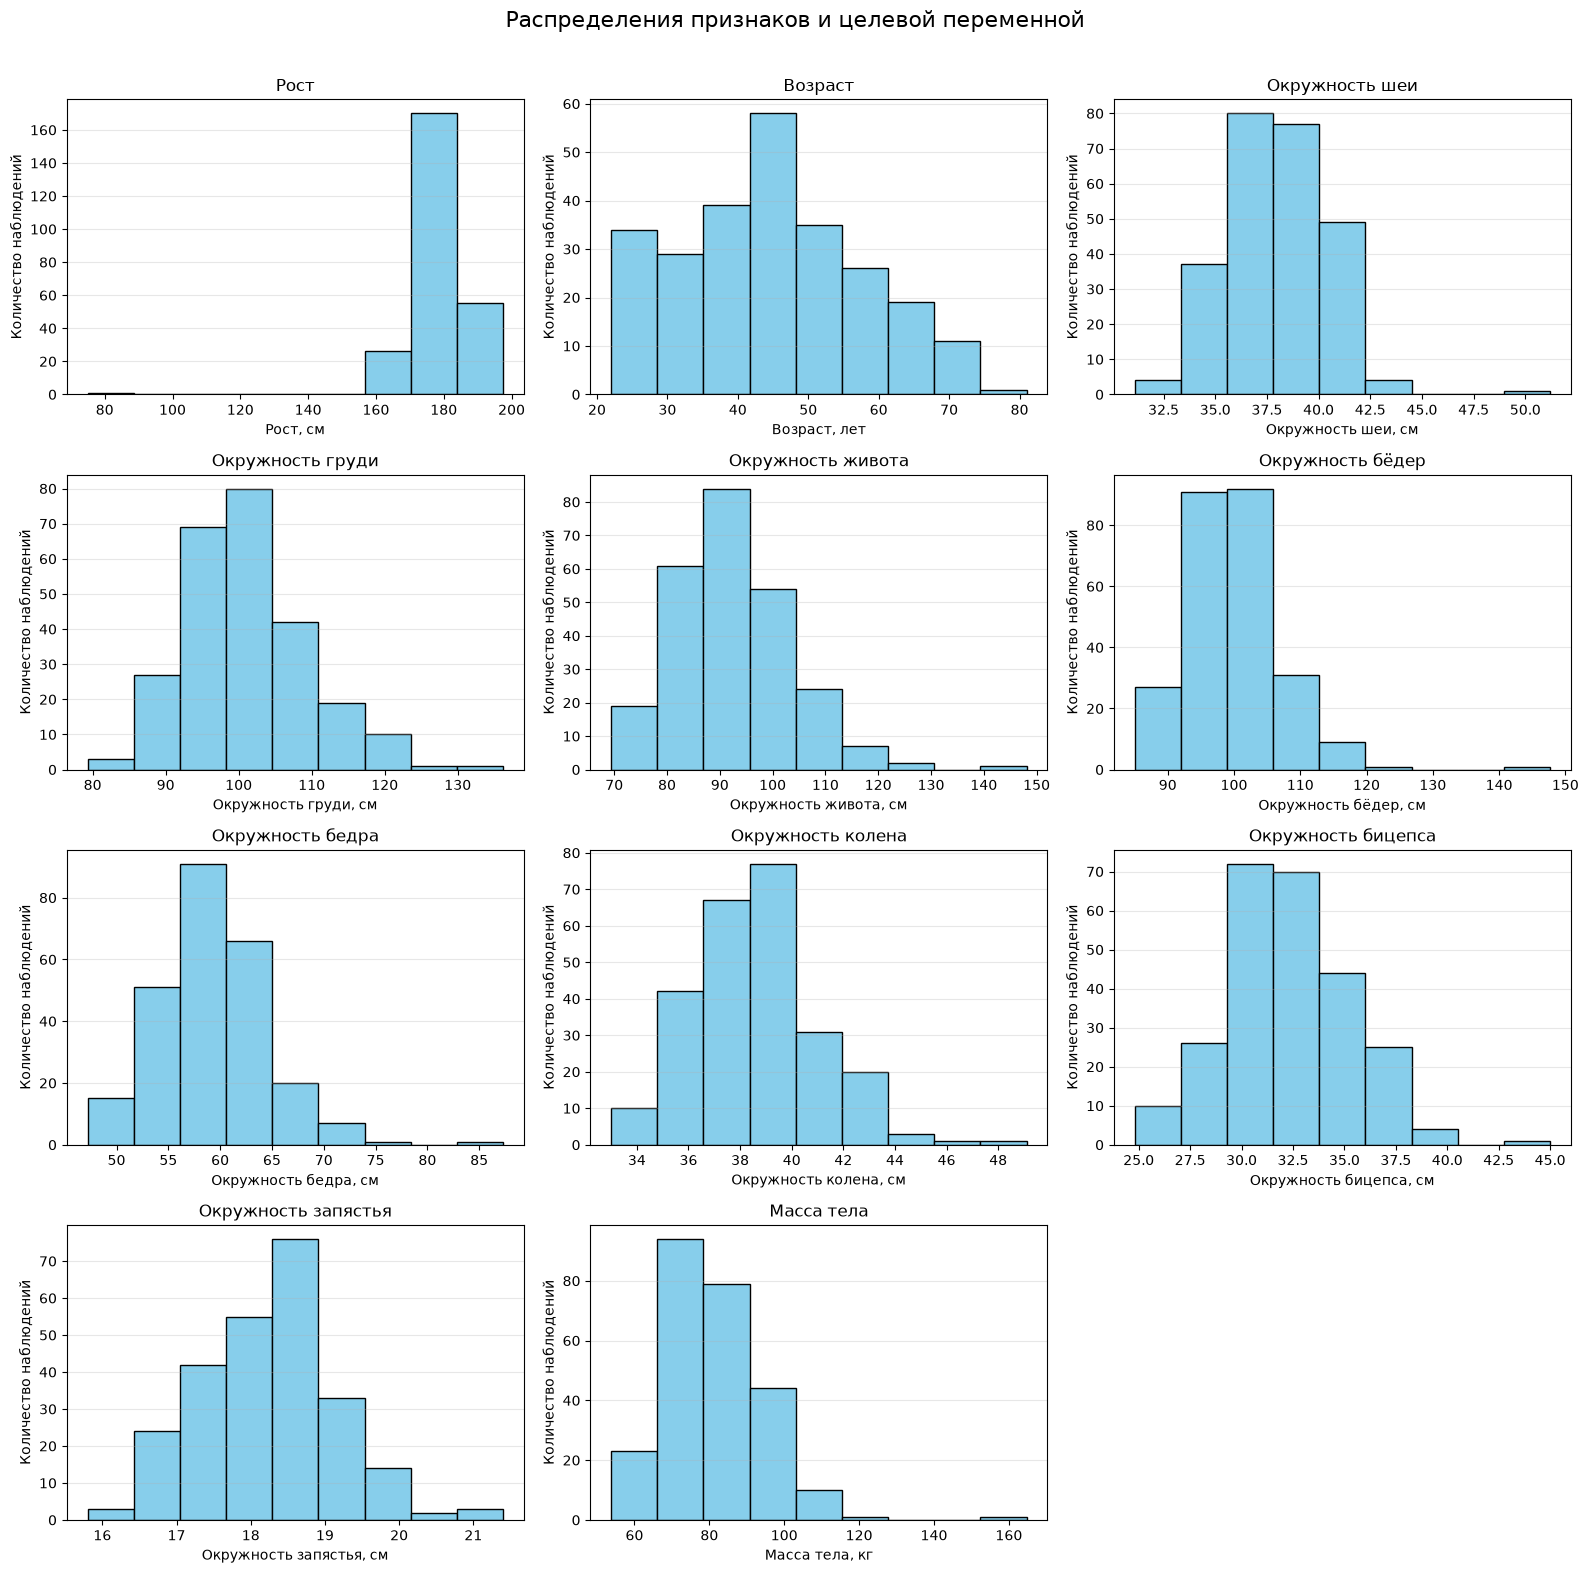

In [120]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.ravel()

for ax, column in zip(axes, df.columns):
    ax.hist(
        df[column].dropna(),
        bins="sturges",
        edgecolor="black",
        color="skyblue"
    )

    ax.set_title(column)

    if column == "Возраст":
        unit = "лет"
    elif column == "Масса тела":
        unit = "кг"
    else:
        unit = "см"

    ax.set_xlabel(f"{column}, {unit}")
    ax.set_ylabel("Количество наблюдений")
    ax.grid(axis="y", alpha=0.3)

for ax in axes[len(df.columns):]:
    ax.set_visible(False)

fig.suptitle("Распределения признаков и целевой переменной", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

<Axes: >

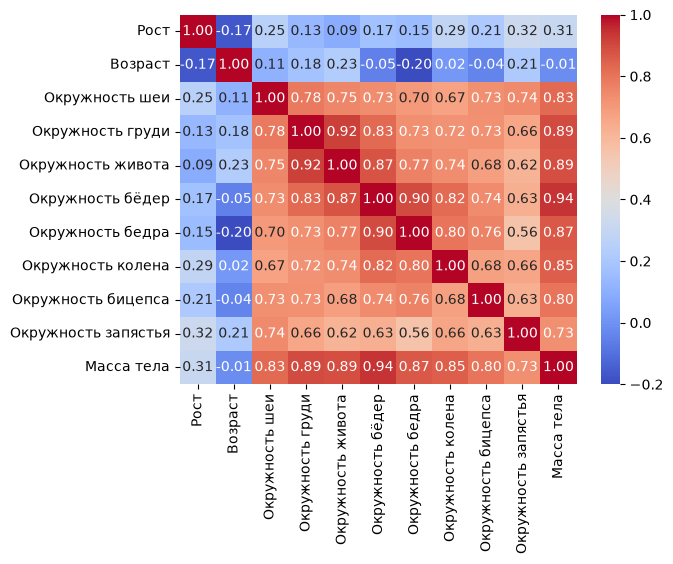

In [121]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

In [123]:
X = df.drop(columns=["Масса тела"])

results = []

for column in X.columns:
    other_features = X.drop(columns=[column])
    feature = X[column]

    model = LinearRegression()
    model.fit(other_features, feature)

    r_squared = model.score(other_features, feature)
    vif = 1 / (1 - r_squared) if r_squared < 1 else float("inf")

    results.append({
        "Признак": column,
        "R²": r_squared,
        "VIF": vif
    })

pd.DataFrame(results)

,Признак,R²,VIF
0,Рост,0.247304,1.328557
1,Возраст,0.511487,2.047027
2,Окружность шеи,0.742503,3.883547
3,Окружность груди,0.870437,7.718243
4,Окружность живота,0.910866,11.219029
5,Окружность бёдер,0.903074,10.317159
6,Окружность бедра,0.871006,7.752294
7,Окружность колена,0.753525,4.057212
8,Окружность бицепса,0.686169,3.186432
9,Окружность запястья,0.662080,2.959279


In [124]:
X = df.drop(columns=["Масса тела"])
y = df["Масса тела"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

linear_model = make_pipeline(StandardScaler(), LinearRegression())
ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
lasso_model = make_pipeline(StandardScaler(), Lasso(alpha=0.1))

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for fold, (train_indices, validation_indices) in enumerate(
    cv.split(X_train), start=1
):
    X_fold_train = X_train.iloc[train_indices]
    y_fold_train = y_train.iloc[train_indices]

    X_fold_validation = X_train.iloc[validation_indices]
    y_fold_validation = y_train.iloc[validation_indices]

    for name, model in [
        ("Линейная", linear_model),
        ("Гребневая", ridge_model),
        ("Lasso", lasso_model)
    ]:
        fold_model = clone(model)
        fold_model.fit(X_fold_train, y_fold_train)

        prediction = fold_model.predict(X_fold_validation)

        actual = y_fold_validation.to_numpy()
        mask = actual != 0

        cv_results.append({
            "Разбиение": fold,
            "Модель": name,
            "RMSE": np.sqrt(
                mean_squared_error(actual, prediction)
            ),
            "R²": r2_score(actual, prediction),
            "MAPE по ненулевым, %":
                mean_absolute_percentage_error(
                    actual[mask], prediction[mask]
                ) * 100 if mask.any() else np.nan
        })

cv_table = pd.DataFrame(cv_results)

display(cv_table.round(4))

cv_mean = cv_table.groupby("Модель")[
    ["RMSE", "R²", "MAPE по ненулевым, %"]
].mean()

display(cv_mean.round(4))

linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

,Разбиение,Модель,RMSE,R²,"MAPE по ненулевым, %"
0,1,Линейная,2.0524,0.9729,2.1523
1,1,Гребневая,2.0462,0.9731,2.1562
2,1,Lasso,2.0716,0.9724,2.1599
3,2,Линейная,2.3188,0.9639,2.3625
4,2,Гребневая,2.3228,0.9637,2.3669
5,2,Lasso,2.3634,0.9625,2.4032
6,3,Линейная,2.4470,0.9618,2.3749
7,3,Гребневая,2.4611,0.9614,2.3814
8,3,Lasso,2.4623,0.9614,2.3800
9,4,Линейная,3.1422,0.9395,2.8844


,RMSE,R²,"MAPE по ненулевым, %"
Модель,,,
Lasso,3.1562,0.9279,2.4867
Гребневая,3.1313,0.9282,2.4716
Линейная,3.1487,0.9272,2.4755


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Рост','Возраст','Окружность шеи',...,'Окружность колена', 'Окружность бицепса','Окружность запястья']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [125]:
y_pred_linear = linear_model.predict(X_test)
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

results = []

for name, prediction in [
    ("Линейная", y_pred_linear),
    ("Гребневая", y_pred_ridge),
    ("Lasso", y_pred_lasso)
]:
    rmse = np.sqrt(mean_squared_error(y_test, prediction))
    r_squared = r2_score(y_test, prediction)

    mape = (
        mean_absolute_percentage_error(y_test, prediction) * 100
        if (y_test != 0).all()
        else np.nan
    )

    results.append({
        "Модель": name,
        "RMSE": rmse,
        "R²": r_squared,
        "MAPE, %": mape
    })

pd.DataFrame(results)

,Модель,RMSE,R²,"MAPE, %"
0,Линейная,2.602735,0.971657,1.928090
1,Гребневая,2.619694,0.971287,1.927523
2,Lasso,2.654564,0.970517,1.952181


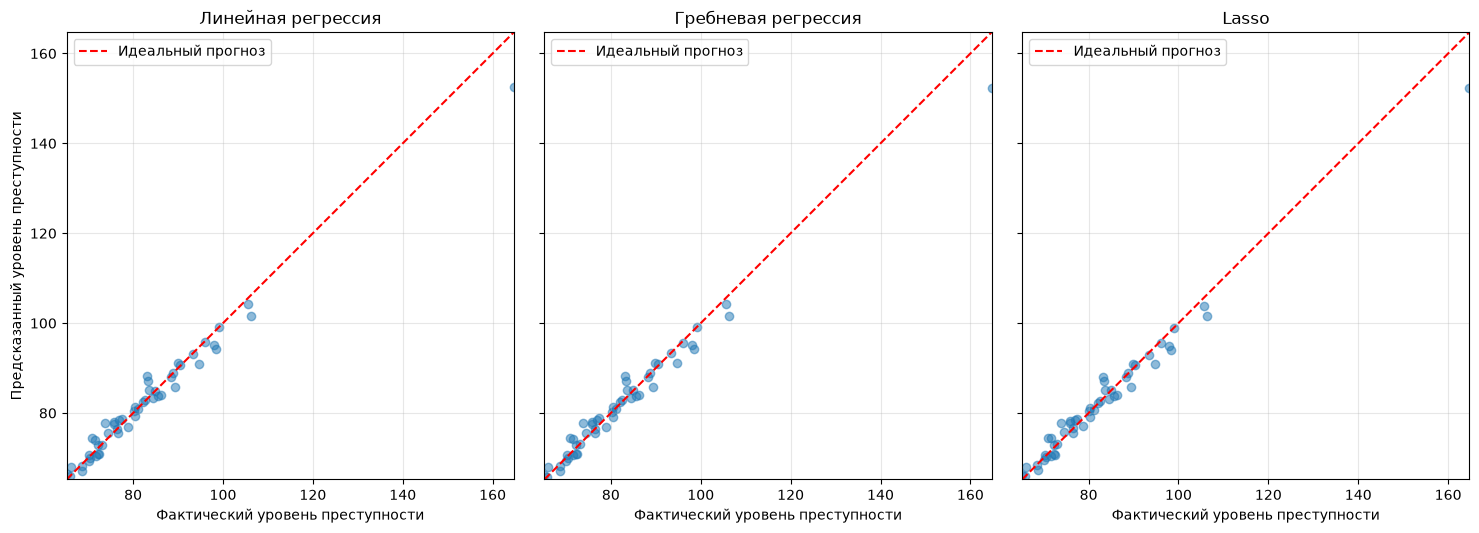

In [126]:
y_pred_linear = linear_model.predict(X_test)
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

lower = min(
    y_test.min(),
    y_pred_linear.min(),
    y_pred_ridge.min(),
    y_pred_lasso.min()
)
upper = max(
    y_test.max(),
    y_pred_linear.max(),
    y_pred_ridge.max(),
    y_pred_lasso.max()
)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), sharex=True, sharey=True
)

for ax, prediction, title in [
    (axes[0], y_pred_linear, "Линейная регрессия"),
    (axes[1], y_pred_ridge, "Гребневая регрессия"),
    (axes[2], y_pred_lasso, "Lasso")
]:
    ax.scatter(y_test, prediction, alpha=0.5)

    ax.plot(
        [lower, upper], [lower, upper],
        "r--", label="Идеальный прогноз"
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.set_xlabel("Фактический уровень преступности")
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Предсказанный уровень преступности")

plt.tight_layout()
plt.show()

In [127]:
scaler_pca = StandardScaler()

X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

cov_matrix = np.cov(X_train_scaled, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

variance_ratio = eigenvalues / eigenvalues.sum()
cumulative_ratio = np.cumsum(variance_ratio)

display(pd.DataFrame({
    "Компонента": range(1, len(eigenvalues) + 1),
    "Собственное значение": eigenvalues,
    "Доля дисперсии": variance_ratio,
    "Накопленная доля": cumulative_ratio
}))

,Компонента,Собственное значение,Доля дисперсии,Накопленная доля
0,1,6.137287,0.610675,0.610675
1,2,1.311672,0.130515,0.741190
2,3,1.014731,0.100968,0.842158
3,4,0.433575,0.043142,0.885300
4,5,0.375811,0.037394,0.922694
5,6,0.298179,0.029670,0.952364
6,7,0.198989,0.019800,0.972164
7,8,0.142952,0.014224,0.986388
8,9,0.075892,0.007551,0.993939
9,10,0.060913,0.006061,1.000000


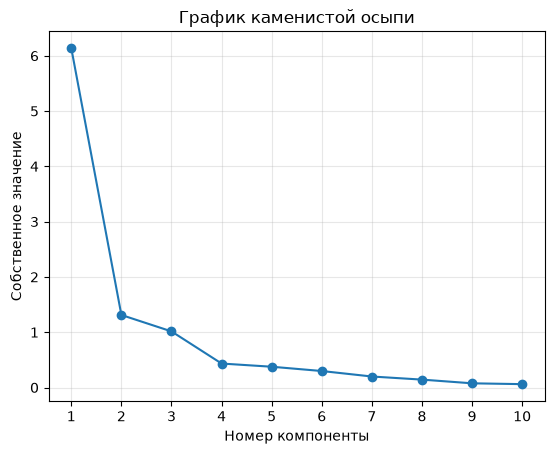

In [128]:
numbers = range(1, len(eigenvalues) + 1)

plt.plot(numbers, eigenvalues, "o-")
plt.xticks(numbers)
plt.xlabel("Номер компоненты")
plt.ylabel("Собственное значение")
plt.title("График каменистой осыпи")
plt.grid(alpha=0.3)
plt.show()

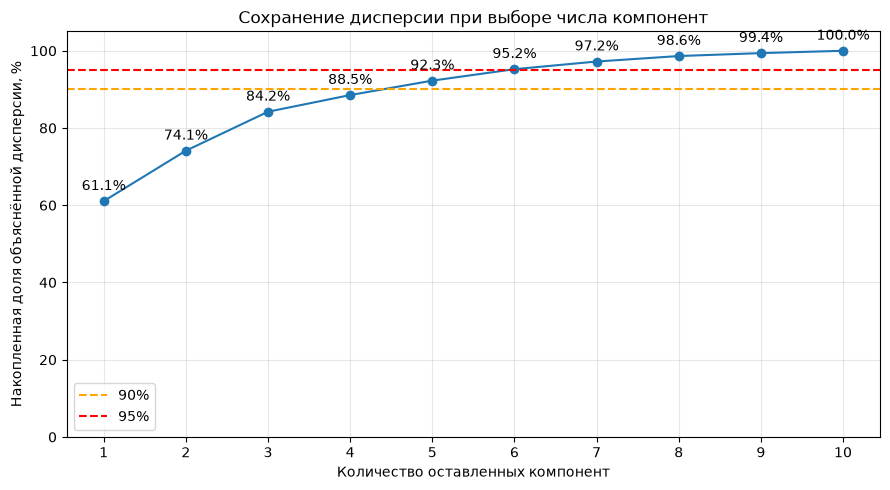

In [129]:
cumulative_variance = np.cumsum(variance_ratio) * 100
numbers = np.arange(1, len(variance_ratio) + 1)

plt.figure(figsize=(9, 5))

plt.plot(numbers, cumulative_variance, "o-")

for k, percent in zip(numbers, cumulative_variance):
    plt.annotate(
        f"{percent:.1f}%",
        (k, percent),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.axhline(90, color="orange", linestyle="--", label="90%")
plt.axhline(95, color="red", linestyle="--", label="95%")

plt.xticks(numbers)
plt.ylim(0, 105)
plt.xlabel("Количество оставленных компонент")
plt.ylabel("Накопленная доля объяснённой дисперсии, %")
plt.title("Сохранение дисперсии при выборе числа компонент")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [130]:
k = 6

cv_pca_results = []

for fold, (train_indices, validation_indices) in enumerate(
    cv.split(X_train), start=1
):
    X_fold_train = X_train.iloc[train_indices]
    y_fold_train = y_train.iloc[train_indices]

    X_fold_validation = X_train.iloc[validation_indices]
    y_fold_validation = y_train.iloc[validation_indices]

    fold_scaler = StandardScaler()

    train_scaled = fold_scaler.fit_transform(X_fold_train)
    validation_scaled = fold_scaler.transform(X_fold_validation)

    fold_cov = np.cov(train_scaled, rowvar=False)

    values, vectors = np.linalg.eigh(fold_cov)
    order = np.argsort(values)[::-1]
    W_fold = vectors[:, order][:, :k]

    train_pca = train_scaled @ W_fold
    validation_pca = validation_scaled @ W_fold

    for name, model in [
        ("Линейная", LinearRegression()),
        ("Гребневая", Ridge(alpha=1.0)),
        ("Lasso", Lasso(alpha=0.01, max_iter=10000))
    ]:
        model.fit(train_pca, y_fold_train)
        prediction = model.predict(validation_pca)

        actual = y_fold_validation.to_numpy()
        mask = actual != 0

        cv_pca_results.append({
            "Разбиение": fold,
            "Модель": name,
            "RMSE": np.sqrt(
                mean_squared_error(actual, prediction)
            ),
            "R²": r2_score(actual, prediction),
            "MAPE по ненулевым, %":
                mean_absolute_percentage_error(
                    actual[mask], prediction[mask]
                ) * 100 if mask.any() else np.nan
        })

cv_pca_table = pd.DataFrame(cv_pca_results)

display(cv_pca_table.round(4))

cv_pca_mean = cv_pca_table.groupby("Модель")[
    ["RMSE", "R²", "MAPE по ненулевым, %"]
].mean()

display(cv_pca_mean.round(4))

,Разбиение,Модель,RMSE,R²,"MAPE по ненулевым, %"
0,1,Линейная,2.1722,0.9697,2.2817
1,1,Гребневая,2.1755,0.9696,2.2857
2,1,Lasso,2.1761,0.9696,2.2882
3,2,Линейная,2.3929,0.9615,2.4105
4,2,Гребневая,2.3954,0.9614,2.4164
5,2,Lasso,2.3935,0.9615,2.4187
6,3,Линейная,2.7313,0.9525,2.5727
7,3,Гребневая,2.7364,0.9523,2.5775
8,3,Lasso,2.7365,0.9523,2.5800
9,4,Линейная,2.9314,0.9474,2.8849


,RMSE,R²,"MAPE по ненулевым, %"
Модель,,,
Lasso,3.2186,0.9247,2.5766
Гребневая,3.2147,0.9249,2.5735
Линейная,3.2258,0.9241,2.5739


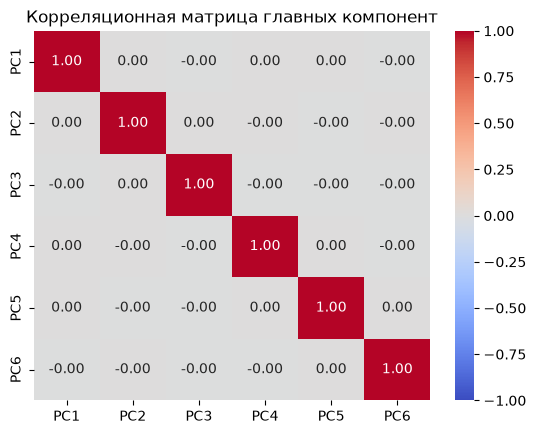

In [131]:
W = eigenvectors[:, :k]

X_train_pca = X_train_scaled @ W
X_test_pca = X_test_scaled @ W

components = pd.DataFrame(
    X_train_pca,
    columns=[f"PC{i + 1}" for i in range(k)]
)

sns.heatmap(
    components.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица главных компонент")
plt.show()

In [132]:
linear_pca = LinearRegression()
ridge_pca = Ridge(alpha=1.0)
lasso_pca = Lasso(alpha=0.01, max_iter=10000)

linear_pca.fit(X_train_pca, y_train)
ridge_pca.fit(X_train_pca, y_train)
lasso_pca.fit(X_train_pca, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.01
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [133]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

mask = y_test.to_numpy() != 0

models = [
    ("Линейная", "Исходные признаки", linear_model, X_test),
    ("Гребневая", "Исходные признаки", ridge_model, X_test),
    ("Lasso", "Исходные признаки", lasso_model, X_test),

    ("Линейная", "PCA", linear_pca, X_test_pca),
    ("Гребневая", "PCA", ridge_pca, X_test_pca),
    ("Lasso", "PCA", lasso_pca, X_test_pca)
]

results = []

for name, features, model, test_data in models:
    prediction = model.predict(test_data)

    results.append({
        "Модель": name,
        "Признаки": features,
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "R²": r2_score(y_test, prediction),
        "MAPE по ненулевым, %":
            mean_absolute_percentage_error(
                y_test.to_numpy()[mask],
                prediction[mask]
            ) * 100 if mask.any() else np.nan
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))

,Модель,Признаки,RMSE,R²,"MAPE по ненулевым, %"
0,Линейная,Исходные признаки,2.6027,0.9717,1.9281
1,Гребневая,Исходные признаки,2.6197,0.9713,1.9275
2,Lasso,Исходные признаки,2.6546,0.9705,1.9522
3,Линейная,PCA,2.6524,0.9706,1.9913
4,Гребневая,PCA,2.6603,0.9704,1.9967
5,Lasso,PCA,2.6566,0.9705,1.9972
